In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from PIL import Image

from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Dropout

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

In [2]:
model = load_model("../models/resnet50_transfer_learning.keras")

print("Transfer Learning model loaded successfully!")

Transfer Learning model loaded successfully!


In [3]:
# Check total layers

print("Total layers:", len(model.layers))

# Check trainable layers

trainable_layers = 0

for layer in model.layers:
    if layer.trainable:
        trainable_layers += 1

print("Trainable layers:", trainable_layers)

Total layers: 179
Trainable layers: 5


In [6]:
# Freeze all layers first

for layer in model.layers:
    layer.trainable = False

# Unfreeze last 20 ResNet50 layers

for layer in model.layers[-24:-4]:
    layer.trainable = True

print("Fine tuning layers unfrozen successfully!")

Fine tuning layers unfrozen successfully!


In [5]:
for layer in model.layers:
    print(layer.name)

input_layer
conv1_pad
conv1_conv
conv1_bn
conv1_relu
pool1_pad
pool1_pool
conv2_block1_1_conv
conv2_block1_1_bn
conv2_block1_1_relu
conv2_block1_2_conv
conv2_block1_2_bn
conv2_block1_2_relu
conv2_block1_0_conv
conv2_block1_3_conv
conv2_block1_0_bn
conv2_block1_3_bn
conv2_block1_add
conv2_block1_out
conv2_block2_1_conv
conv2_block2_1_bn
conv2_block2_1_relu
conv2_block2_2_conv
conv2_block2_2_bn
conv2_block2_2_relu
conv2_block2_3_conv
conv2_block2_3_bn
conv2_block2_add
conv2_block2_out
conv2_block3_1_conv
conv2_block3_1_bn
conv2_block3_1_relu
conv2_block3_2_conv
conv2_block3_2_bn
conv2_block3_2_relu
conv2_block3_3_conv
conv2_block3_3_bn
conv2_block3_add
conv2_block3_out
conv3_block1_1_conv
conv3_block1_1_bn
conv3_block1_1_relu
conv3_block1_2_conv
conv3_block1_2_bn
conv3_block1_2_relu
conv3_block1_0_conv
conv3_block1_3_conv
conv3_block1_0_bn
conv3_block1_3_bn
conv3_block1_add
conv3_block1_out
conv3_block2_1_conv
conv3_block2_1_bn
conv3_block2_1_relu
conv3_block2_2_conv
conv3_block2_2_bn
co

In [7]:
# Make classification layers trainable

for layer in model.layers[-4:]:
    layer.trainable = True

print("Classification layers are trainable!")

Classification layers are trainable!


In [8]:
trainable_layers = 0

for layer in model.layers:
    if layer.trainable:
        trainable_layers += 1

print("Total Layers:", len(model.layers))
print("Trainable Layers:", trainable_layers)
print("Non-trainable Layers:", len(model.layers) - trainable_layers)

Total Layers: 179
Trainable Layers: 24
Non-trainable Layers: 155


In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine tuning model compiled successfully!")

Fine tuning model compiled successfully!


In [10]:
dataset_path = "../data/raw/NEU-DET"

train_images = dataset_path + "/train/Images"
val_images = dataset_path + "/validation/Images"

image_size = 224

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Dataset paths set successfully!")
print("Classes:", classes)

Dataset paths set successfully!
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [11]:
X_train = []
y_train = []

X_val = []
y_val = []

# Load training images
for i, class_name in enumerate(classes):
    folder_path = os.path.join(train_images, class_name)

    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)

        img = Image.open(image_path).convert("RGB")
        img = img.resize((image_size, image_size))

        X_train.append(np.array(img))
        y_train.append(i)

# Load validation images
for i, class_name in enumerate(classes):
    folder_path = os.path.join(val_images, class_name)

    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)

        img = Image.open(image_path).convert("RGB")
        img = img.resize((image_size, image_size))

        X_val.append(np.array(img))
        y_val.append(i)

# Convert lists into NumPy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)

X_val = np.array(X_val)
y_val = np.array(y_val)

print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Validation data shape:", X_val.shape)
print("Validation labels shape:", y_val.shape)

Training data shape: (1440, 224, 224, 3)
Training labels shape: (1440,)
Validation data shape: (360, 224, 224, 3)
Validation labels shape: (360,)


In [12]:
X_train = preprocess_input(X_train)
X_val = preprocess_input(X_val)

print("Training data preprocessing completed!")
print("Validation data preprocessing completed!")

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training data preprocessing completed!
Validation data preprocessing completed!
Minimum pixel value: -123.68
Maximum pixel value: 151.061


In [13]:
history_fine = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accuracy: 0.9701 - loss: 0.0890 - val_accuracy: 0.9889 - val_loss: 0.0439
Epoch 2/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.9965 - loss: 0.0201 - val_accuracy: 0.9861 - val_loss: 0.0511
Epoch 3/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.9979 - loss: 0.0103 - val_accuracy: 0.9861 - val_loss: 0.0579
Epoch 4/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.9986 - loss: 0.0069 - val_accuracy: 0.9778 - val_loss: 0.0652
Epoch 5/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.9986 - loss: 0.0057 - val_accuracy: 0.9750 - val_loss: 0.0652


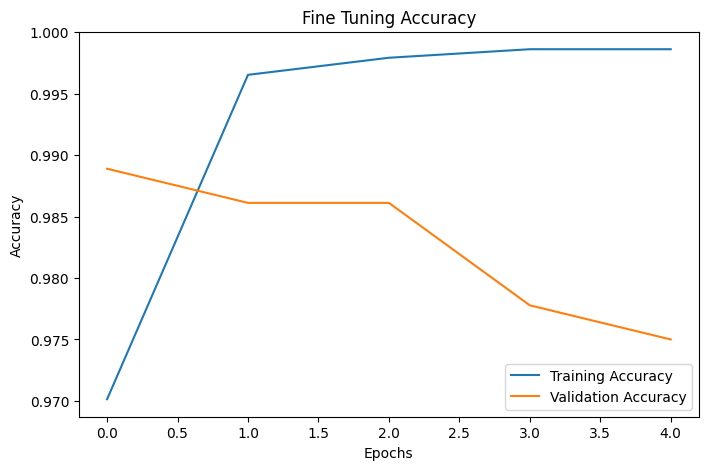

In [14]:
plt.figure(figsize=(8,5))

plt.plot(history_fine.history['accuracy'], label='Training Accuracy')
plt.plot(history_fine.history['val_accuracy'], label='Validation Accuracy')

plt.title("Fine Tuning Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

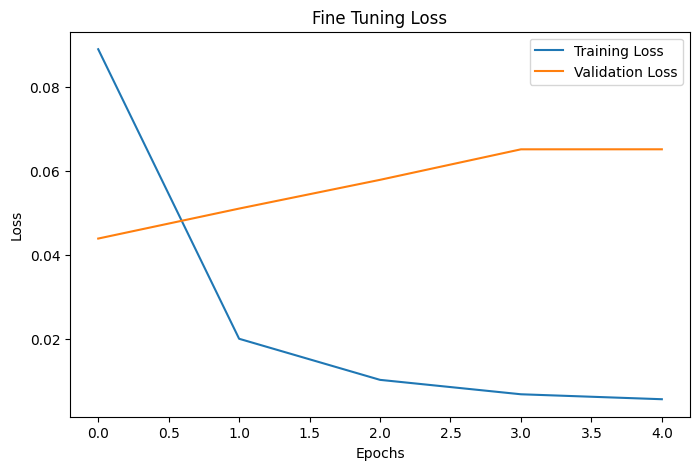

In [15]:
plt.figure(figsize=(8,5))

plt.plot(history_fine.history['loss'], label='Training Loss')
plt.plot(history_fine.history['val_loss'], label='Validation Loss')

plt.title("Fine Tuning Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [16]:
test_loss, test_accuracy = model.evaluate(X_val, y_val)

print("Fine Tuning Test Loss:", test_loss)
print("Fine Tuning Test Accuracy:", test_accuracy * 100)

12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9750 - loss: 0.0652
Fine Tuning Test Loss: 0.06516498327255249
Fine Tuning Test Accuracy: 97.50000238418579


In [17]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_val)

y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(
    y_val,
    y_pred_classes,
    target_names=classes
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        60
      inclusion       1.00      0.85      0.92        60
        patches       1.00      1.00      1.00        60
 pitted_surface       0.97      1.00      0.98        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       0.90      1.00      0.94        60

       accuracy                           0.97       360
      macro avg       0.98      0.97      0.97       360
   weighted avg       0.98      0.97      0.97       360



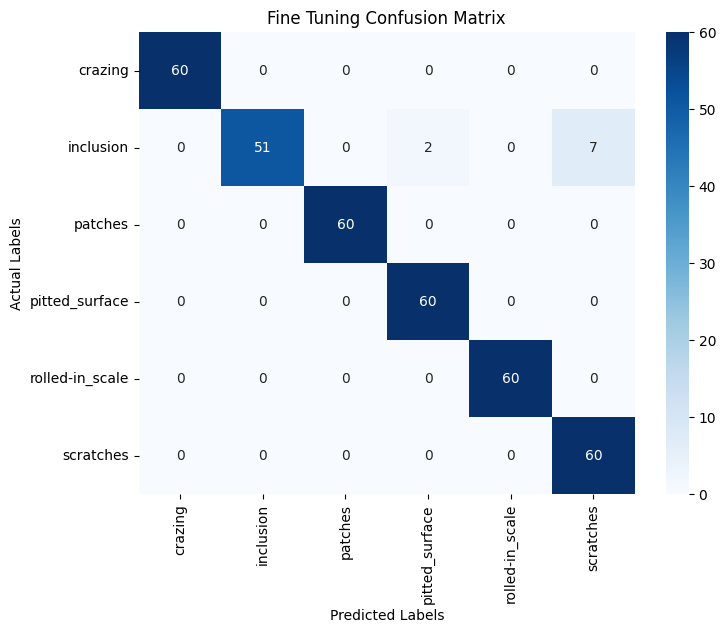

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_val, y_pred_classes)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("Fine Tuning Confusion Matrix")

plt.show()

In [19]:
model.save("../models/resnet50_fine_tuned.keras")

print("Fine-Tuned Model Saved Successfully!")

Fine-Tuned Model Saved Successfully!
